# Basic Usage

## Get DataFrames from tables

The `fc_to_df()` and `fc_to_gdf()` methods fetch tables from FileGeodatabases, Enterprise Geodatabases, MapServers, and the memory workspace.

### Fetch a non-spatial table

Fetching a non-spatial table is essentially the same as calling `arcpy.da.TableToArrowTable(...).to_pandas()`. However, `fc_to_df()` performs existence checks on the data itself and the requested fields, convenient for interactive prototyping.

In [6]:
from arcpy_arrow import fc_to_df

EXAMPLE_TABLE = "https://sampleserver6.arcgisonline.com/arcgis/rest/services/NYTimes_Covid19Cases_USCounties/MapServer/5"

covid_cases_sd = fc_to_df(EXAMPLE_TABLE,
                            where_clause="state = 'South Dakota'",
                            field_names=["date", "cases", "deaths"]
                            )


print(covid_cases_sd.head())

                 date  cases  deaths
0 2020-03-10 04:00:00      5       1
1 2020-03-11 04:00:00      8       1
2 2020-03-12 04:00:00      8       1
3 2020-03-13 04:00:00      9       1
4 2020-03-14 04:00:00      9       1


Request a non-existent table, and the function raises

In [22]:
fc_to_df("memory/nonexistent_feature_class",
         where_clause="state = 'South Dakota'",
         field_names=["date", "cases", "deaths"]
         )

FileNotFoundError: Feature Class does not exist: memory/nonexistent_feature_class

Similarly, requesting a non-existent field raises a verbose error

In [23]:
fc_to_df(EXAMPLE_TABLE,
         where_clause="state = 'South Dakota'",
         field_names=["date", "cases", "deths"] # typo in field
         )

ValueError: The requested fields do not exist: deths

The provided errors are more verbose than the `arcpy` default `RuntimeError`

In [25]:
from arcpy.da import TableToArrowTable

TableToArrowTable("blorp")

RuntimeError: Arrow: DataStore input is not valid

## Fetch a spatial table

`fc_to_gdf()` fetches Well-Known-Binary values for each geometry and uses `shapely` to load them into a GeoDataFrame. 

The GeoDataFrame's Coordinate Reference System is determined using an `arcpy.Describe()` call. If the SpatialReference is not set, the user can provide a `fallback_crs`. Once the GeoDataFrame is constructed, the user can ask that it be transformed to a `to_crs` before it's returned.

In [4]:
from arcpy_arrow import fc_to_gdf

ESRI_CITIES = "https://sampleserver6.arcgisonline.com/arcgis/rest/services/USA/MapServer/0"

sd_cities_gdf = fc_to_gdf(ESRI_CITIES, 
          where_clause = "st = 'SD'",
          shape_col="shape")

print(sd_cities_gdf.head().to_markdown())

|    |   objectid | areaname   | class   | st   | capital   |   pop2000 | geometry                                       |
|---:|-----------:|:-----------|:--------|:-----|:----------|----------:|:-----------------------------------------------|
|  0 |       2963 | Aberdeen   | city    | SD   | N         |     24658 | POINT (-98.48129103099996 45.46370789500003)   |
|  1 |       2964 | Brookings  | city    | SD   | N         |     18504 | POINT (-96.78810501899994 44.30625305400008)   |
|  2 |       2965 | Huron      | city    | SD   | N         |     11893 | POINT (-98.21815188699998 44.35914498900007)   |
|  3 |       2966 | Mitchell   | city    | SD   | N         |     14558 | POINT (-98.02628212199994 43.71389604600006)   |
|  4 |       2967 | Pierre     | city    | SD   | Y         |     13876 | POINT (-100.33637804599994 44.367965930000025) |


## Build Feature Classes from DataFrames

Get a DataFrame/GeoDataFrame as a Table/FeatureClass in a file geodatabase, enterprise geodatabase, or memory workspace. 

DataFrame schemas are sanitized to match ESRI's esoteric expectations for inputted Arrow objects, embedded with the required metadata, and converted to a feature class or table.

This example demonstrates a full round trip, using a toy dataset of U.S. cities.

### 1. Fetch a `pandas` DataFrame of coordinates

In [3]:
import pandas as pd

EXAMPLE_CSV_DATA = "https://gist.githubusercontent.com/steinbring/e5417af6d1bb95742555866c84e3f91d/raw/186b532887c9738687860aeae5de7a7b2a0ed233/cityStateToLatLong.csv"

cities_df = (pd.read_csv(EXAMPLE_CSV_DATA)
                .rename(columns = lambda c: c.strip())
             )


cities_df.head()

,state,city,latitude,longitude
0,AL,Abanda CDP,33.091627,-85.527029
1,AL,Abbeville city,31.564724,-85.259123
2,AL,Adamsville city,33.602315,-86.971527
3,AL,Addison town,34.202681,-87.178004
4,AL,Akron town,32.879066,-87.740899


### 2. Build a `geopandas` GeoDataFrame

<Axes: >

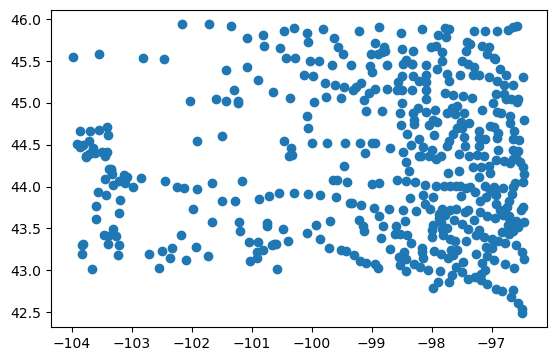

In [ ]:
import geopandas as gpd

city_pts = gpd.points_from_xy(
    x = cities_df["longitude"],
    y = cities_df["latitude"]
)

cities_gdf = gpd.GeoDataFrame(
    data = cities_df,
    geometry = city_pts
).set_crs(4269)

(cities_gdf
        .plot()
)

### 3. Build the feature class

In [16]:
from arcpy_arrow import df_to_fc
from arcpy import Describe

cities_fc = df_to_fc(
    df = cities_gdf,
    fc = None
)

Describe(cities_fc)

catalogPath,memory/fc_413aa92f7e194ff182563630ed35ec77
dataType,FeatureClass
shapeType,Point
hasM,False
hasZ,False
OBJECTID,OID
Shape,Geometry
state,String
city,String
latitude,Double
longitude,Double


<Axes: >

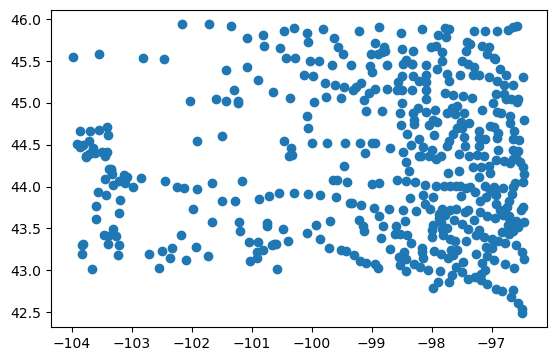

In [11]:
from arcpy_arrow import fc_to_gdf

(fc_to_gdf(cities_fc, where_clause = "state = 'SD'")
    .plot()
 )